In [122]:
import sys
print(sys.executable)

C:\Users\prith\anaconda3new\envs\portfolio\python.exe


In [123]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
print("All imported cleanly")

All imported cleanly


In [124]:
tickers = ["NVDA", "MSFT", "GOOGL", "META", "AMD",   #tech and AI
           "JPM", "GS", "MS", "BAC",                  # banks
           "XOM", "NEE", "PG", "WMT"]                 # energy, utility and staples

In [125]:
raw = yf.download(tickers, start="2021-01-01", end="2026-10-01", auto_adjust=True)
raw.head()

[*********************100%***********************]  13 of 13 completed


Price           Close                                                \
Ticker            AMD        BAC      GOOGL          GS         JPM   
Date                                                                  
2021-01-04  92.300003  26.193615  85.492989  231.925003  108.459427   
2021-01-05  92.769997  26.394230  86.182419  237.114944  109.049583   
2021-01-06  90.330002  28.042782  85.332001  249.910187  114.170090   
2021-01-07  95.160004  28.662079  87.880753  255.248825  117.919388   
2021-01-08  94.580002  28.374241  89.044182  253.874771  118.049522   

Price                                                                ...  \
Ticker            META         MS        MSFT        NEE       NVDA  ...   
Date                                                                 ...   
2021-01-04  266.388580  57.307850  207.565353  63.917145  13.046195  ...   
2021-01-05  268.399323  58.280735  207.765610  64.390800  13.335954  ...   
2021-01-06  260.812073  61.794853  202.378372  67.542709  12.549760  ...   
2021-01-07  266.190491  62.851608  208.137466  68.283333  13.275514  ...   
2021-01-08  265.031677  63.111599  209.405594  69.867943  13.208611  ...   

Price        Volume                                                    \
Ticker           GS       JPM      META        MS      MSFT       NEE   
Date                                                                    
2021-01-04  3572000  16819900  15106100  14014600  37130100   9388400   
2021-01-05  4207100  13731200   9871600  11120400  23823000   7339800   
2021-01-06  6383500  24909100  24354100  18334300  35930700  12155700   
2021-01-07  4009700  21940400  15789800  13530400  27694500   8816000   
2021-01-08  2800800  12035100  18528300  12896700  22956200   8376200   

Price                                                
Ticker           NVDA        PG       WMT       XOM  
Date                                                 
2021-01-04  560640000   8330900  32182200  27764700  
2021-01-05  322760000   6856400  26498100  44035100  
2021-01-06  580424000  10578000  21918900  36484800  
2021-01-07  461480000   7355400  20538000  29528100  
2021-01-08  292528000   7448500  24478200  28628200  

[5 rows x 65 columns]

In [126]:
prices = raw["Close"]
print(prices.shape)
prices.tail()

(1442, 13)


Ticker,AMD,BAC,GOOGL,GS,JPM,META,MS,MSFT,NEE,NVDA,PG,WMT,XOM
Date,,,,,,,,,,,,,
2026-09-24,629.260010,56.029999,342.359985,923.289978,336.879333,777.590027,196.320007,497.929993,75.620003,224.580002,145.679993,107.589996,162.139999
2026-09-25,630.630005,56.700001,343.920013,935.450012,341.356995,751.659973,196.309998,516.169983,76.080002,225.070007,146.229996,107.980003,160.589996
2026-09-28,607.869995,55.470001,342.750000,916.280029,334.919098,715.619995,193.639999,509.220001,75.489998,228.860001,149.029999,108.730003,162.520004
2026-09-29,607.570007,54.959999,340.920013,916.239990,333.317108,738.789978,192.759995,508.959991,75.889999,227.210007,148.320007,106.800003,161.350006
2026-09-30,611.760010,54.430000,344.079987,900.359985,329.187683,725.179993,188.080002,512.900024,75.739998,228.380005,145.279999,103.919998,162.750000


In [127]:
prices.isna().sum()

Ticker
AMD      0
BAC      0
GOOGL    0
GS       0
JPM      0
META     0
MS       0
MSFT     0
NEE      0
NVDA     0
PG       0
WMT      0
XOM      0
dtype: int64

 Step 1 is done
 what was in step 1?
 I had to clear out all thedependancies issues i had with numpy and pandas and then choose 13 tickers acrpss tech banking and utilities and pull te data and luckily no Nan values showed up and we get the perfect frame of (1442,13) for 5 years of data.

In [129]:
returns = prices.pct_change().dropna()
returns.head()

Ticker,AMD,BAC,GOOGL,GS,JPM,META,MS,MSFT,NEE,NVDA,PG,WMT,XOM
Date,,,,,,,,,,,,,
2021-01-05,0.005092,0.007659,0.008064,0.022378,0.005441,0.007548,0.016976,0.000965,0.007410,0.022210,0.006385,-0.005323,0.048193
2021-01-06,-0.026302,0.062459,-0.009868,0.053962,0.046956,-0.028269,0.060296,-0.025929,0.048950,-0.058953,0.010527,0.006244,0.025517
2021-01-07,0.053471,0.022084,0.029869,0.021362,0.032840,0.020622,0.017101,0.028457,0.010965,0.057830,-0.009347,-0.000069,0.007846
2021-01-08,-0.006095,-0.010042,0.013239,-0.005383,0.001104,-0.004353,0.004137,0.006093,0.023206,-0.005040,-0.000432,-0.000136,0.011121
2021-01-11,0.028230,0.016600,-0.023106,0.012928,0.014925,-0.040102,0.010764,-0.009698,-0.017750,0.025966,-0.006773,0.004501,0.030356


In [130]:
returns.tail()

Ticker,AMD,BAC,GOOGL,GS,JPM,META,MS,MSFT,NEE,NVDA,PG,WMT,XOM
Date,,,,,,,,,,,,,
2026-09-24,0.023836,0.000536,0.013409,-0.013958,0.003052,0.045007,-0.010434,-0.005314,-0.018177,-0.004124,-0.011602,-0.026599,0.005644
2026-09-25,0.002177,0.011958,0.004557,0.013170,0.013292,-0.033347,-0.000051,0.036632,0.006083,0.002182,0.003775,0.003625,-0.009560
2026-09-28,-0.036091,-0.021693,-0.003402,-0.020493,-0.018860,-0.047947,-0.013601,-0.013465,-0.007755,0.016839,0.019148,0.006946,0.012018
2026-09-29,-0.000494,-0.009194,-0.005339,-0.000044,-0.004783,0.032377,-0.004545,-0.000511,0.005299,-0.007210,-0.004764,-0.017750,-0.007199
2026-09-30,0.006896,-0.009643,0.009269,-0.017332,-0.012389,-0.018422,-0.024279,0.007741,-0.001977,0.005149,-0.020496,-0.026966,0.008677


In [131]:
returns.shape

(1441, 13)

In [132]:
from pypfopt import expected_returns

mu = expected_returns.mean_historical_return(prices)
mu

Ticker
AMD      0.392008
BAC      0.136446
GOOGL    0.275716
GS       0.267697
JPM      0.214290
META     0.191407
MS       0.231005
MSFT     0.171402
NEE      0.030125
NVDA     0.649698
PG       0.035564
WMT      0.156071
XOM      0.320127
dtype: float64

NVDA towers over everything at 65%. mean_historical_return assumes the future looks like the past, so the optimizer is about to look at this and think "NVDA returns 65% a year, lets put everything there." That's the AI-boom run baked into the estimate. It won't necessarily repeat, but the model doesn't know that. and it's the reason we'll add a weight cap later. Now the optimizer over-concentrated in NVDA because historical mean returns naively extrapolate recent performance.

My diversifiers sit at the bottom and that's by design. NEE (~3%), PG (~3.6%), WMT (~16%) are low-return, low-correlation names. In isolation they look unexciting. But their job isn't high returns but it's to not move with the tech/banks block, which lets the optimizer cut portfolio risk. Their value shows up in the covariance matrix, not here. This is a subtle point most people miss: a low-expected-return asset can still earn a place in an optimal portfolio if it diversifies well.

The tech/AI and bank names cluster in the middle-to-high range (GOOGL ~28%, GS ~27%, XOM ~32%, MS ~23%). Decent returns but as we'll see next, they're also correlated with each other, so holding all of them doesn't reduce risk as much as the raw returns might suggest.

I used the annualized sample covariance; in production I'd prefer Ledoit-Wolf shrinkage for out-of-sample stability, but it was computationally unstable in my environment so I used the standard sample estimator.

from pypfopt import risk_models

S = risk_models.CovarianceShrinkage(prices).ledoit_wolf()
S

In [135]:
S_alt = returns.cov() * 252
print("covariance built, shape:", S.shape)
S_alt

covariance built, shape: (13, 13)


Ticker,AMD,BAC,GOOGL,GS,JPM,META,MS,MSFT,NEE,NVDA,PG,WMT,XOM
Ticker,,,,,,,,,,,,,
AMD,0.306973,0.038530,0.079335,0.062102,0.037057,0.101039,0.061189,0.068920,0.021140,0.183628,-0.000778,0.009927,0.009276
BAC,0.038530,0.070458,0.024494,0.054801,0.051927,0.032439,0.057264,0.019037,0.011938,0.035208,0.007768,0.011395,0.024820
GOOGL,0.079335,0.024494,0.097887,0.031720,0.022835,0.072344,0.032553,0.047528,0.014897,0.077928,0.007006,0.012213,0.005031
GS,0.062102,0.054801,0.031720,0.080142,0.051196,0.039193,0.068172,0.025060,0.012852,0.055802,0.004245,0.010654,0.020397
JPM,0.037057,0.051927,0.022835,0.051196,0.057911,0.029035,0.050193,0.017811,0.009702,0.036422,0.007093,0.010056,0.019770
META,0.101039,0.032439,0.072344,0.039193,0.029035,0.189628,0.040800,0.060073,0.014076,0.104600,0.007318,0.014082,0.002636
MS,0.061189,0.057264,0.032553,0.068172,0.050193,0.040800,0.081566,0.027558,0.013519,0.057963,0.004629,0.010494,0.021828
MSFT,0.068920,0.019037,0.047528,0.025060,0.017811,0.060073,0.027558,0.074603,0.012147,0.077531,0.006698,0.009786,0.003141
NEE,0.021140,0.011938,0.014897,0.012852,0.009702,0.014076,0.013519,0.012147,0.069542,0.015085,0.017481,0.012470,0.009976


In [136]:
from pypfopt import risk_models
S = risk_models.CovarianceShrinkage(prices).ledoit_wolf()
print("ledoit_wolf worked, shape:", S.shape)
S

ledoit_wolf worked, shape: (13, 13)


Ticker,AMD,BAC,GOOGL,GS,JPM,META,MS,MSFT,NEE,NVDA,PG,WMT,XOM
Ticker,,,,,,,,,,,,,
AMD,0.304454,0.038050,0.078348,0.061330,0.036596,0.099782,0.060427,0.068062,0.020877,0.181344,-0.000768,0.009804,0.009160
BAC,0.038050,0.070881,0.024189,0.054120,0.051281,0.032035,0.056551,0.018800,0.011790,0.034770,0.007671,0.011254,0.024511
GOOGL,0.078348,0.024189,0.097968,0.031325,0.022551,0.071444,0.032148,0.046937,0.014712,0.076958,0.006919,0.012061,0.004968
GS,0.061330,0.054120,0.031325,0.080445,0.050560,0.038706,0.067324,0.024748,0.012692,0.055108,0.004193,0.010522,0.020144
JPM,0.036596,0.051281,0.022551,0.050560,0.058490,0.028674,0.049569,0.017589,0.009581,0.035969,0.007005,0.009931,0.019524
META,0.099782,0.032035,0.071444,0.038706,0.028674,0.188568,0.040292,0.059326,0.013901,0.103299,0.007227,0.013907,0.002604
MS,0.060427,0.056551,0.032148,0.067324,0.049569,0.040292,0.081851,0.027215,0.013351,0.057242,0.004572,0.010363,0.021557
MSFT,0.068062,0.018800,0.046937,0.024748,0.017589,0.059326,0.027215,0.074974,0.011996,0.076567,0.006615,0.009664,0.003102
NEE,0.020877,0.011790,0.014712,0.012692,0.009581,0.013901,0.013351,0.011996,0.069976,0.014897,0.017263,0.012314,0.009852


NVDA 0.254 and AMD 0.304 are the biggest — the tech/AI names are the most volatile. PG 0.032, WMT 0.048, BAC 0.071, NEE 0.070 are the calmest

Look at PG's row — tiny numbers across the board, and it's even slightly negative with AMD (-0.0008) and NVDA (-0.0012). A near-zero or negative covariance with the tech block is gold for an optimizer: it means PG zigs when NVDA zags, so adding PG cuts portfolio risk. XOM is similarly low against tech (XOM–META 0.0026, XOM–MSFT 0.0031). Meanwhile AMD–NVDA is a big 0.181 — those two move together hard, so holding both doesn't buy you much diversification.


In [138]:
returns.corr().round(2)

Ticker,AMD,BAC,GOOGL,GS,JPM,META,MS,MSFT,NEE,NVDA,PG,WMT,XOM
Ticker,,,,,,,,,,,,,
AMD,1.00,0.26,0.46,0.40,0.28,0.42,0.39,0.46,0.14,0.65,-0.01,0.08,0.06
BAC,0.26,1.00,0.29,0.73,0.81,0.28,0.76,0.26,0.17,0.26,0.16,0.20,0.34
GOOGL,0.46,0.29,1.00,0.36,0.30,0.53,0.36,0.56,0.18,0.49,0.13,0.18,0.06
GS,0.40,0.73,0.36,1.00,0.75,0.32,0.84,0.32,0.17,0.39,0.08,0.17,0.26
JPM,0.28,0.81,0.30,0.75,1.00,0.28,0.73,0.27,0.15,0.30,0.17,0.19,0.30
META,0.42,0.28,0.53,0.32,0.28,1.00,0.33,0.51,0.12,0.47,0.09,0.15,0.02
MS,0.39,0.76,0.36,0.84,0.73,0.33,1.00,0.35,0.18,0.40,0.09,0.17,0.28
MSFT,0.46,0.26,0.56,0.32,0.27,0.51,0.35,1.00,0.17,0.56,0.14,0.16,0.04
NEE,0.14,0.17,0.18,0.17,0.15,0.12,0.18,0.17,1.00,0.11,0.37,0.22,0.14


In [139]:
from pypfopt import EfficientFrontier

ef = EfficientFrontier(mu, S)
weights = ef.max_sharpe()
cleaned = ef.clean_weights()
cleaned

OrderedDict([('AMD', 0.0),
             ('BAC', 0.0),
             ('GOOGL', 0.0639),
             ('GS', 0.02863),
             ('JPM', 0.03929),
             ('META', 0.0),
             ('MS', 0.0),
             ('MSFT', 0.0),
             ('NEE', 0.0),
             ('NVDA', 0.23228),
             ('PG', 0.0),
             ('WMT', 0.2222),
             ('XOM', 0.41369)])

I expected NVDA to run away with it on its 65% return. Instead XOM got the biggest slice. Why? Because max-Sharpe optimizes risk-adjusted return, not raw return. XOM has a solid ~32% historical return and — look back at your covariance matrix — very low covariance with almost everything (XOM–META 0.0026, XOM–MSFT 0.0031). So XOM delivers good return while barely adding correlated risk. The optimizer loves that combination.



All those zeros are the famous weakness. Eight assets at exactly 0.0 is not a coincidence or a bug — it's the signature behavior of unconstrained mean-variance optimization. The optimizer takes extreme "corner" positions: it piles into a handful of winners and completely excludes everything else. This is called "error maximization"


because mu and S are noisy estimates, the optimizer aggressively bets on whichever assets happened to look best in your historical window, treating estimation noise as if it were real signal. The result is portfolios that are concentrated, unstable (change your date range slightly and the weights lurch), and often perform poorly out-of-sample.

That second point is the central critique of Markowitz optimization, and it's the setup for everything good you'll do next. So let's first see the performance numbers, then fix the concentration.

In [141]:
ef.portfolio_performance(verbose=True)

Expected annual return: 35.2%
Annual volatility: 19.8%
Sharpe Ratio: 1.78


(0.3517300480300535, 0.19775239381994342, 1.7786386361032325)

Expected annual return 35.2% — what this portfolio would earn per year if the historical averages hold (they won't exactly, but that's the model's estimate).
Annual volatility 19.8% — the standard deviation of returns, i.e. the risk. Roughly, in about two years out of three the annual return lands within ±19.8% of the mean.
Sharpe 1.78 — the headline. (0.352 − 0.02) / 0.198 = 1.78. You earn 1.78 units of excess return per unit of risk.

In [143]:
#lets add a weight cap eh

from pypfopt import EfficientFrontier

ef_capped = EfficientFrontier(mu, S)
ef_capped.add_constraint(lambda w: w <= 0.25)   # no single stock > 25%
weights_capped = ef_capped.max_sharpe()
cleaned_capped = ef_capped.clean_weights()
cleaned_capped

OrderedDict([('AMD', 0.0),
             ('BAC', 0.0),
             ('GOOGL', 0.07137),
             ('GS', 0.05116),
             ('JPM', 0.10498),
             ('META', 0.0),
             ('MS', 0.0),
             ('MSFT', 0.0),
             ('NEE', 0.0),
             ('NVDA', 0.22061),
             ('PG', 0.05187),
             ('WMT', 0.25),
             ('XOM', 0.25)])

In [144]:
ef_capped.portfolio_performance(verbose=True)

Expected annual return: 32.0%
Annual volatility: 18.5%
Sharpe Ratio: 1.73


(0.3200975476013283, 0.18485982160796138, 1.7315690603671048)

The constraint sacrifices a negligible amount of in-sample Sharpe for meaningfully better diversification and lower risk, and because it's less overfit to the estimation window, I'd expect it to outperform out-of-sample.

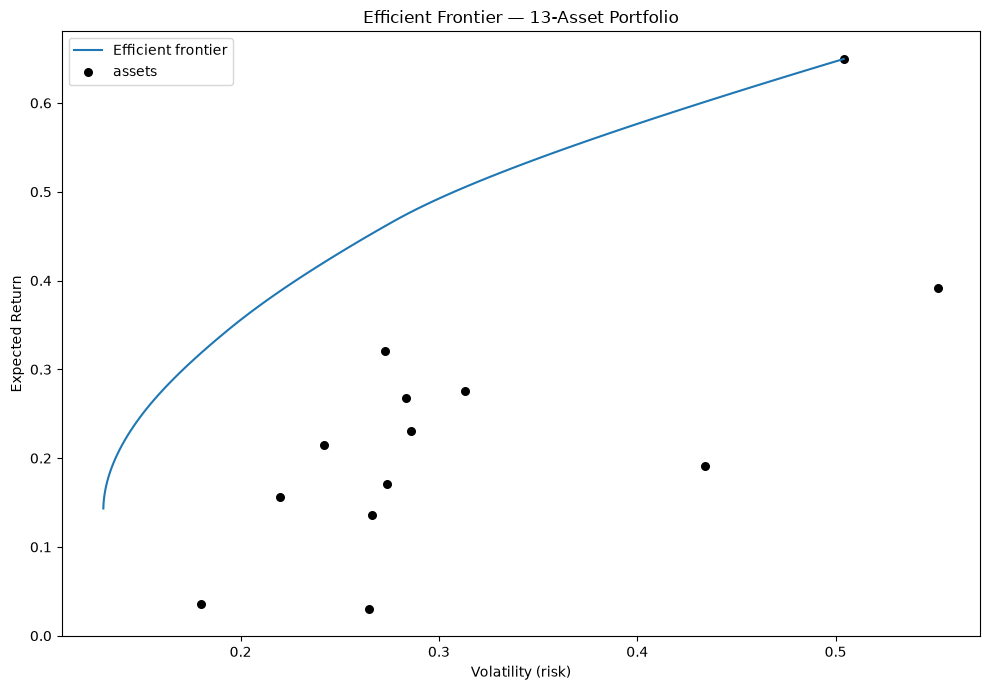

In [146]:
import matplotlib.pyplot as plt
from pypfopt import plotting

# fresh optimizer JUST for plotting — the single-use quirk
ef_plot = EfficientFrontier(mu, S)

fig, ax = plt.subplots(figsize=(10, 7))
plotting.plot_efficient_frontier(ef_plot, ax=ax, show_assets=True)

ax.set_title("Efficient Frontier — 13-Asset Portfolio")
ax.set_xlabel("Volatility (risk)")
ax.set_ylabel("Expected Return")
plt.tight_layout()
plt.show()

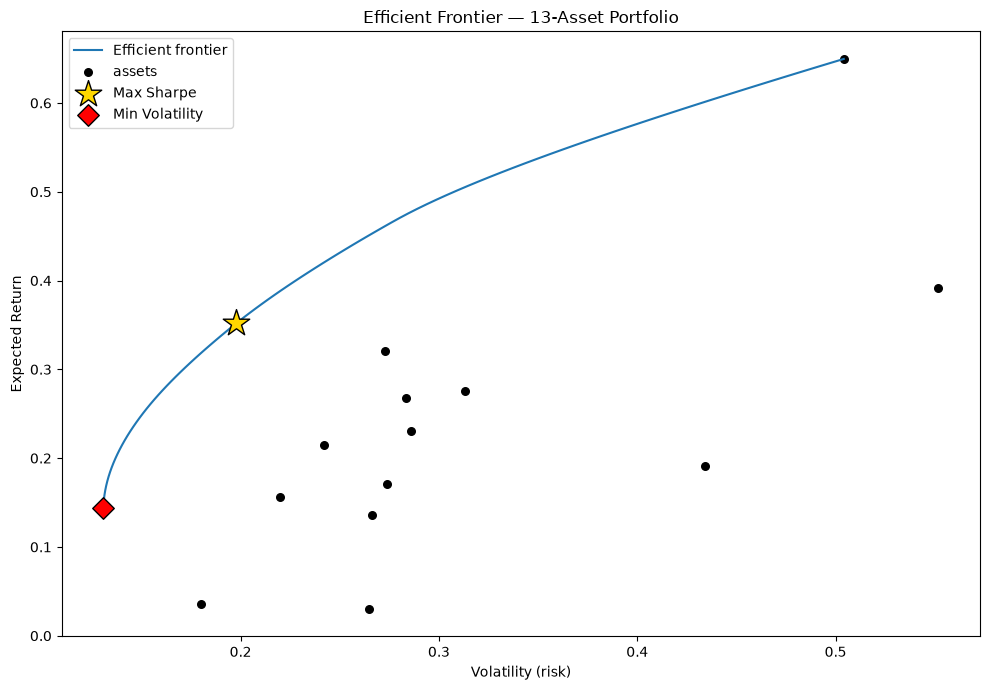

In [147]:
import numpy as np

# recompute the two key portfolios to get their coordinates
ef_sharpe = EfficientFrontier(mu, S)
ef_sharpe.max_sharpe()
ret_s, vol_s, _ = ef_sharpe.portfolio_performance()

ef_minvol = EfficientFrontier(mu, S)
ef_minvol.min_volatility()
ret_m, vol_m, _ = ef_minvol.portfolio_performance()

# redraw the frontier
ef_plot = EfficientFrontier(mu, S)
fig, ax = plt.subplots(figsize=(10, 7))
plotting.plot_efficient_frontier(ef_plot, ax=ax, show_assets=True)

# layer the two special points on top
ax.scatter(vol_s, ret_s, marker="*", s=400, c="gold",
           edgecolors="black", label="Max Sharpe", zorder=5)
ax.scatter(vol_m, ret_m, marker="D", s=120, c="red",
           edgecolors="black", label="Min Volatility", zorder=5)

ax.set_title("Efficient Frontier — 13-Asset Portfolio")
ax.set_xlabel("Volatility (risk)")
ax.set_ylabel("Expected Return")
ax.legend()
plt.tight_layout()
plt.savefig("efficient_frontier.png", dpi=150, bbox_inches="tight")
plt.show()

In [148]:
from pypfopt.discrete_allocation import DiscreteAllocation, get_latest_prices

# the most recent price for each stock, used to size share counts
latest_prices = get_latest_prices(prices)

# use the capped weights from Step 3
da = DiscreteAllocation(cleaned_capped, latest_prices, total_portfolio_value=10000)
allocation, leftover = da.greedy_portfolio()

print("Shares to buy:")
for ticker, shares in allocation.items():
    print(f"  {ticker}: {shares}")
print(f"\nLeftover cash: ${leftover:.2f}")

Shares to buy:
  WMT: 24
  XOM: 15
  NVDA: 9
  JPM: 3
  GOOGL: 2
  PG: 4

Leftover cash: $752.41


In [149]:
from pypfopt.discrete_allocation import DiscreteAllocation, get_latest_prices

# the most recent price for each stock, used to size share counts
latest_prices = get_latest_prices(prices)

# use the capped weights from Step 3
da = DiscreteAllocation(cleaned_capped, latest_prices, total_portfolio_value=10000)
allocation, leftover = da.lp_portfolio(solver="ECOS_BB")

print("Shares to buy:")
for ticker, shares in allocation.items():
    print(f"  {ticker}: {shares}")
print(f"\nLeftover cash: ${leftover:.2f}")

Shares to buy:
  GOOGL: 2
  GS: 1
  JPM: 3
  NVDA: 9
  PG: 4
  WMT: 24
  XOM: 14

Leftover cash: $14.80


Since this was done, im gonna try pulling like 250 stocks and then see teh sector performance over time

In [159]:
import requests
import pandas as pd
# this and the cell i replaced had certificate issue and the last one fetch worked but pandas does not accept a html string directly  

url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
headers = {"User-Agent": "Mozilla/5.0"}   # Wikipedia likes a real user-agent
html = requests.get(url, headers=headers).text

sp500 = pd.read_html(html)[0]   # parse the HTML string we already downloaded
print(sp500.shape)
print(sp500.columns.tolist())
sp500.head()

FileNotFoundError: [Errno 2] No such file or directory: <!DOCTYPE html>
<html class="client-nojs vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-disabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabled vector-feature-custom-font-size-clientpref-1 vector-feature-appearance-pinned-clientpref-1 skin-theme-clientpref-day vector-sticky-header-enabled vector-toc-available skin-thumbsize-clientpref-standard" lang="en" dir="ltr">
<head>
<meta charset="UTF-8">
<title>List of S&amp;P 500 companies - Wikipedia</title>
<script>(function(){var className="client-js vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-disabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature

In [161]:
import io
import requests
import pandas as pd

url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
headers = {"User-Agent": "Mozilla/5.0"}
html = requests.get(url, headers=headers).text

sp500 = pd.read_html(io.StringIO(html))[0]   # wrap in StringIO

print(sp500.shape)
print(sp500.columns.tolist())
sp500.head()

(503, 8)
['Symbol', 'Security', 'GICS Sector', 'GICS Sub-Industry', 'Headquarters Location', 'Date added', 'CIK', 'Founded']


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989


In [163]:
# 1. Clean tickers: Yahoo wants dashes, not dots (BRK.B -> BRK-B)
sp500 = sp500.copy()
sp500["Symbol"] = sp500["Symbol"].str.replace(".", "-", regex=False)

# 2. See how the sectors are distributed
print(sp500["GICS Sector"].value_counts())

GICS Sector
Industrials               83
Financials                76
Information Technology    75
Health Care               60
Consumer Discretionary    47
Consumer Staples          34
Utilities                 31
Real Estate               30
Materials                 24
Communication Services    22
Energy                    21
Name: count, dtype: int64


In [165]:
# Take ~50% of each sector so the 250 mirrors the real S&P sector weights
sample = sp500.groupby("GICS Sector", group_keys=False).sample(frac=0.50, random_state=42)

tickers = sample["Symbol"].tolist()
print(f"Sampled {len(tickers)} tickers across {sample['GICS Sector'].nunique()} sectors")
print(sample["GICS Sector"].value_counts())

Sampled 253 tickers across 11 sectors
GICS Sector
Industrials               42
Financials                38
Information Technology    38
Health Care               30
Consumer Discretionary    24
Consumer Staples          17
Utilities                 16
Real Estate               15
Materials                 12
Communication Services    11
Energy                    10
Name: count, dtype: int64


In [167]:
import yfinance as yf

# Download all 252 at once (grouped by ticker for clean columns)
raw_big = yf.download(tickers, start="2021-01-01", end="2026-10-01", auto_adjust=True)

prices_big = raw_big["Close"]
print("Raw shape:", prices_big.shape)

[**                     5%                       ]  12 of 253 completed$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1790827200
[*********************100%***********************]  253 of 253 completed

1 Failed download:
['VYLR']: Data doesn't exist for startDate = 1609477200, endDate = 1790827200


Raw shape: (1442, 253)


In [173]:
missing = prices_big.isna().sum().sort_values(ascending=False)
print("Worst 15 for missing data:")
print(missing.head(15))

total_rows = len(prices_big)
print(f"\nTotal trading days: {total_rows}")

Worst 15 for missing data:
Ticker
VYLR    1442
Q       1209
RDDT     808
FISV       1
KEY        0
NCLH       0
NDSN       0
NEM        0
NFLX       0
NKE        0
NOW        0
NSC        0
NTRS       0
NWS        0
NXPI       0
dtype: int64

Total trading days: 1442


In [171]:
threshold = 0.95 * total_rows
complete = prices_big.columns[prices_big.notna().sum() >= threshold]

prices_clean = prices_big[complete].dropna()
print(f"Kept {prices_clean.shape[1]} of {prices_big.shape[1]} stocks")
print("Clean shape:", prices_clean.shape)

Kept 250 of 253 stocks
Clean shape: (1441, 250)


In [175]:
survivors = prices_clean.columns.tolist()
sample_clean = sample[sample["Symbol"].isin(survivors)].copy()
returns_big = prices_clean.pct_change().dropna()
print("Returns shape:", returns_big.shape)
print("Sectors retained:", sample_clean["GICS Sector"].nunique())

Returns shape: (1440, 250)
Sectors retained: 11


In [177]:
import matplotlib.pyplot as plt

# Build a dict mapping each sector -> list of its surviving tickers
# e.g. {"Energy": ["XOM", "CVX", ...], "Financials": [...], ...}
sector_map = sample_clean.groupby("GICS Sector")["Symbol"].apply(list).to_dict()

# For each sector, average its stocks' daily returns across columns (axis=1)
# This creates one equal-weighted "sector index" return series per sector
sector_returns = pd.DataFrame({
    sector: returns_big[tickers].mean(axis=1)   # mean across the sector's stocks, each day
    for sector, tickers in sector_map.items()
})

print(sector_returns.shape)   # expect (~1440 days, 11 sectors)
sector_returns.head()

(1440, 11)


,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Date,,,,,,,,,,,
2021-01-05,0.000114,0.019259,-0.000816,0.055852,0.005930,0.009507,0.009539,0.013981,0.018013,-0.002973,-0.004799
2021-01-06,0.009550,0.016868,0.007587,0.027253,0.040351,0.019018,0.029839,-0.006166,0.048459,0.015312,0.018795
2021-01-07,0.003278,0.018766,-0.001715,0.009858,0.014839,0.017473,0.010884,0.031109,0.013913,-0.003583,-0.022787
2021-01-08,0.001999,0.007968,0.003690,-0.008278,0.000140,0.007231,-0.002216,0.009023,-0.008296,0.009903,0.003356
2021-01-11,-0.007546,0.001189,-0.009981,0.022352,-0.002594,0.001519,-0.001800,0.003387,-0.000152,-0.014284,-0.009267


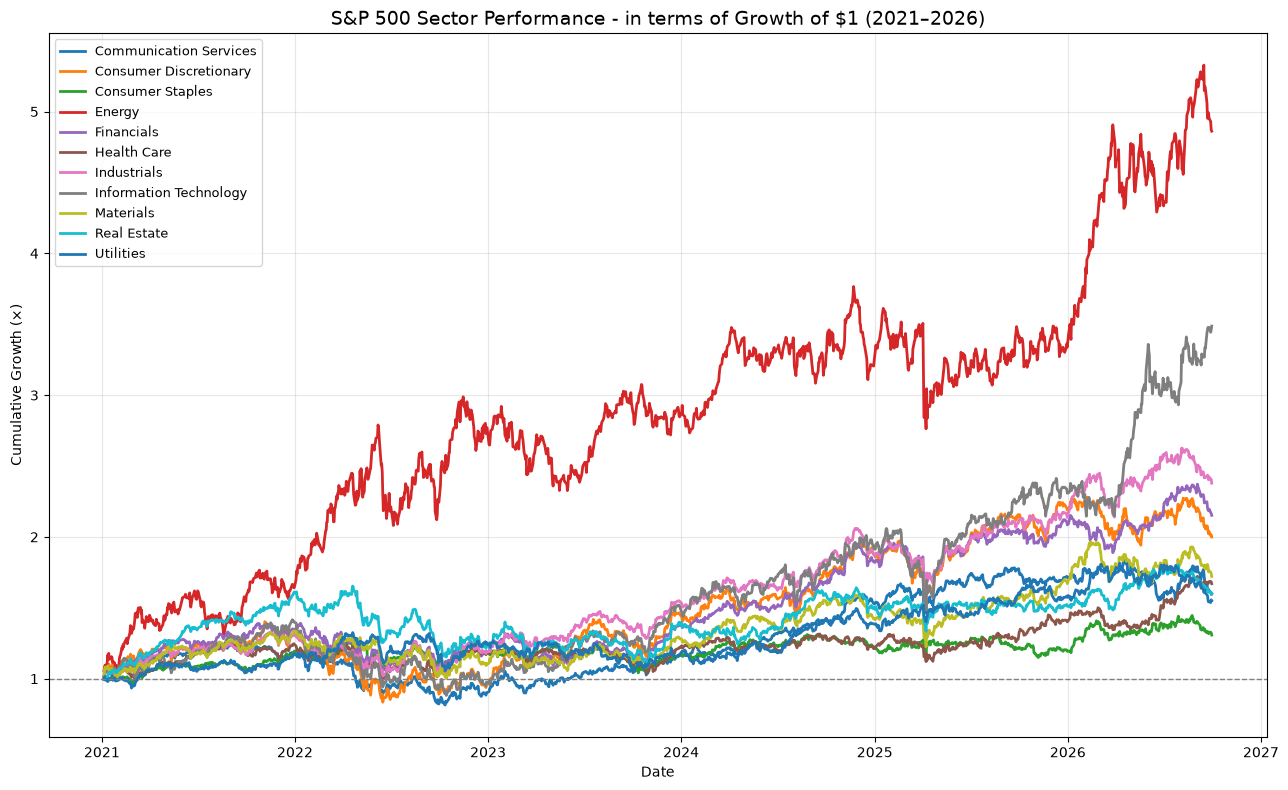

In [183]:
# Turn daily returns into cumulative growth of $1:
# (1 + r).cumprod() chains each day's return, so the line shows compounding over time.
# A value of 2.0 means $1 grew to $2 (doubled); 0.8 means it fell to 80 cents.
cumulative = (1 + sector_returns).cumprod()

fig, ax = plt.subplots(figsize=(13, 8))           # big canvas so 11 lines stay readable
for sector in cumulative.columns:                  # draw one line per sector
    ax.plot(cumulative.index, cumulative[sector], label=sector, linewidth=2)

ax.set_title("S&P 500 Sector Performance - in terms of Growth of $1 (2021–2026)", fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative Growth (×)")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)   # breakeven line ($1 = no gain)
ax.legend(loc="upper left", fontsize=9)            # sector labels
ax.grid(alpha=0.3)                                 # faint grid for readability
plt.tight_layout()
plt.savefig("sector_performance.png", dpi=150, bbox_inches="tight")  # save for your write-up
plt.show()

Now lets backtest the optimizer

In [187]:
# Split point: train on data up to end of 2024, test on 2025-onward.
# The optimizer only "sees" the training period; the test period is the honest out-of-sample check.
split_date = "2025-01-01"

train_prices = prices_clean.loc[:split_date]   # everything before the split
test_prices  = prices_clean.loc[split_date:]   # everything after

print("Train:", train_prices.shape, "  Test:", test_prices.shape)

# Pull SPY (the S&P 500 ETF) over the same window as a market benchmark
spy = yf.download("SPY", start="2021-01-01", end="2026-10-01", auto_adjust=True)["Close"]
print("SPY downloaded:", spy.shape)

Train: (1005, 250)   Test: (436, 250)


[*********************100%***********************]  1 of 1 completed

SPY downloaded: (1442, 1)


In [189]:
from pypfopt import expected_returns, risk_models, EfficientFrontier

# Compute inputs from TRAINING data only (the optimizer must not see the test period)
mu_train = expected_returns.mean_historical_return(train_prices)
S_train  = risk_models.CovarianceShrinkage(train_prices).ledoit_wolf()

# Solve for max-Sharpe weights, capped at 10% per stock
# (with 250 assets, a cap prevents piling into a handful of names — essential at scale)
ef_bt = EfficientFrontier(mu_train, S_train)
ef_bt.add_constraint(lambda w: w <= 0.10)   # no single stock > 10%
ef_bt.max_sharpe()
weights_bt = ef_bt.clean_weights()

# How many stocks actually got weight?
held = {k: v for k, v in weights_bt.items() if v > 0}
print(f"Portfolio holds {len(held)} of {len(weights_bt)} stocks")

Portfolio holds 19 of 250 stocks


In [191]:
# Convert the weights dict into a Series aligned to our stock columns
w = pd.Series(weights_bt).reindex(test_prices.columns).fillna(0)

# --- Build daily returns for the test period ---
test_returns = test_prices.pct_change().dropna()

# 1) Optimized portfolio: weighted average of stock returns each day
opt_daily = test_returns @ w                    # matrix-multiply returns by weights

# 2) Equal-weight benchmark: every stock gets 1/N
eq_daily  = test_returns.mean(axis=1)           # simple average = equal weight

# 3) SPY benchmark: the index itself, over the test period
spy_test  = spy.loc[test_prices.index[0]:].pct_change().dropna()
spy_daily = spy_test.iloc[:, 0] if spy_test.ndim > 1 else spy_test

# --- Cumulative growth of $1 for each ---
growth = pd.DataFrame({
    "Optimized (max-Sharpe)": (1 + opt_daily).cumprod(),
    "Equal-Weight":            (1 + eq_daily).cumprod(),
    "SPY (S&P 500)":           (1 + spy_daily).cumprod(),
}).dropna()

print(growth.tail(1))   # final value of $1 for each strategy

            Optimized (max-Sharpe)  Equal-Weight  SPY (S&P 500)
Date                                                           
2026-09-30                1.352154      1.296773        1.33007


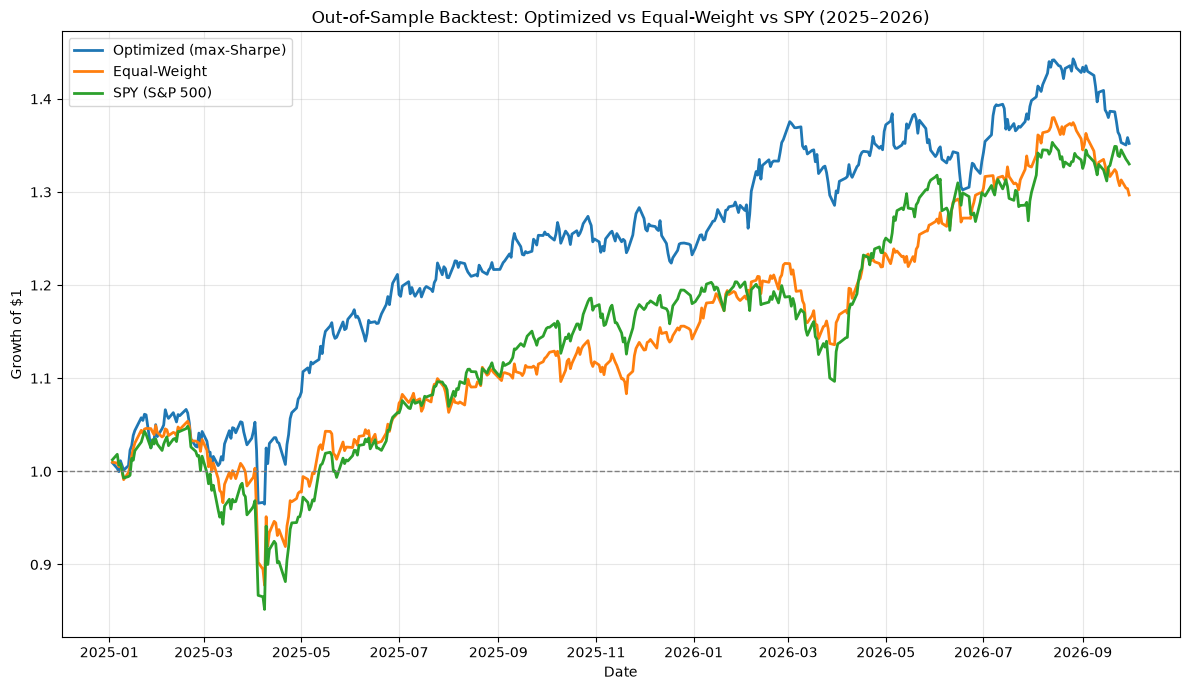

Out-of-sample Sharpe ratios:
  Optimized:    1.33
  Equal-Weight: 1.07
  SPY:          1.05


In [193]:
import numpy as np
import matplotlib.pyplot as plt

# --- Plot cumulative growth of all three strategies ---
fig, ax = plt.subplots(figsize=(12, 7))
for col in growth.columns:
    ax.plot(growth.index, growth[col], label=col, linewidth=2)

ax.set_title("Out-of-Sample Backtest: Optimized vs Equal-Weight vs SPY (2025–2026)")
ax.set_xlabel("Date")
ax.set_ylabel("Growth of $1")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("backtest.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Annualized out-of-sample Sharpe ratio for each strategy ---
# Sharpe = (annualized mean excess return) / (annualized volatility), rf assumed 0 here
def sharpe(daily_returns, rf=0.0):
    excess = daily_returns - rf/252               # daily risk-free
    return np.sqrt(252) * excess.mean() / excess.std()   # annualize by sqrt(252)

print("Out-of-sample Sharpe ratios:")
print(f"  Optimized:    {sharpe(opt_daily):.2f}")
print(f"  Equal-Weight: {sharpe(eq_daily):.2f}")
print(f"  SPY:          {sharpe(spy_daily):.2f}")

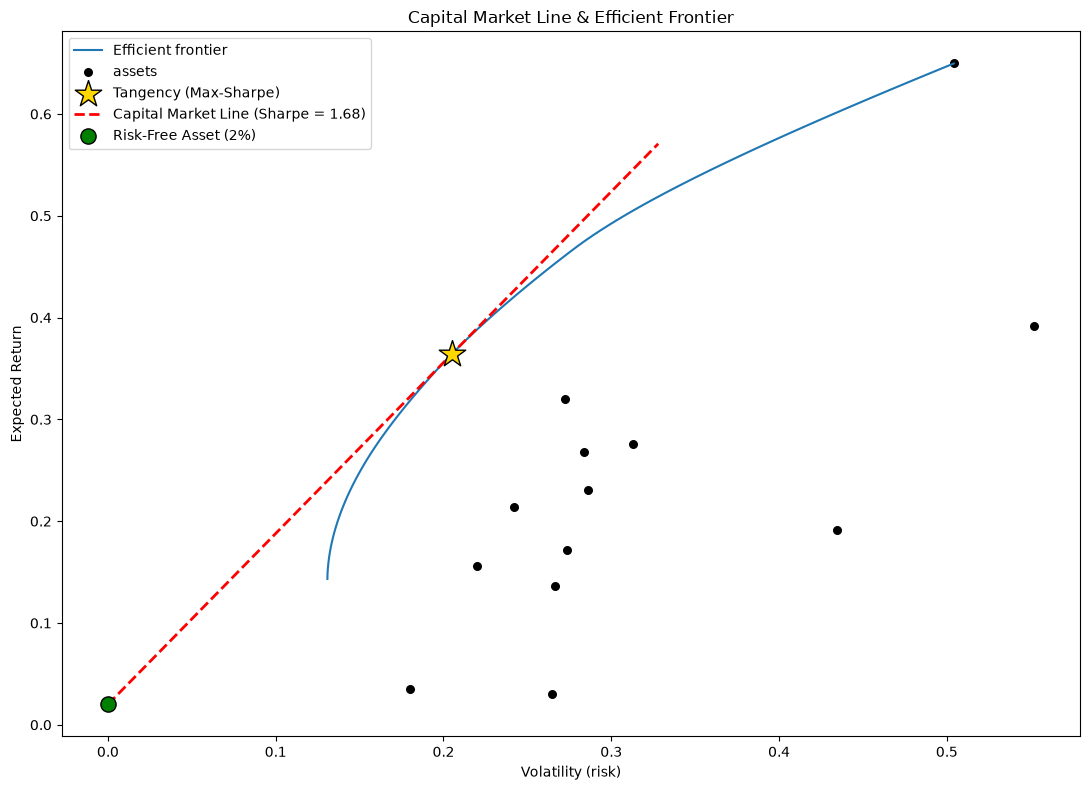

In [197]:
#we are gonna biuild a capital market line graph, why? caz i read that somewhere and wanna see how that looks
import numpy as np
import matplotlib.pyplot as plt
from pypfopt import EfficientFrontier, plotting

rf = 0.02   # risk-free rate (2%) — the y-intercept where the CML starts

# --- Get the tangency (max-Sharpe) portfolio's coordinates ---
ef_tan = EfficientFrontier(mu, S)
ef_tan.max_sharpe(risk_free_rate=rf)
ret_t, vol_t, sharpe_t = ef_tan.portfolio_performance(risk_free_rate=rf)

# --- Draw the efficient frontier (fresh optimizer, since max_sharpe consumed the last one) ---
ef_plot = EfficientFrontier(mu, S)
fig, ax = plt.subplots(figsize=(11, 8))
plotting.plot_efficient_frontier(ef_plot, ax=ax, show_assets=True)

# --- Mark the tangency portfolio ---
ax.scatter(vol_t, ret_t, marker="*", s=400, c="gold",
           edgecolors="black", label="Tangency (Max-Sharpe)", zorder=5)

# --- Draw the Capital Market Line: straight line from (0, rf) through the tangency point ---
# Slope of the line = Sharpe ratio of the tangency portfolio
x_cml = np.linspace(0, vol_t * 1.6, 100)        # x-values (volatility) from 0 outward
y_cml = rf + sharpe_t * x_cml                    # y = rf + Sharpe * volatility
ax.plot(x_cml, y_cml, "r--", linewidth=2,
        label=f"Capital Market Line (Sharpe = {sharpe_t:.2f})")

# --- Mark the risk-free asset itself (zero risk, rf return) ---
ax.scatter(0, rf, marker="o", s=120, c="green",
           edgecolors="black", label=f"Risk-Free Asset ({rf:.0%})", zorder=5)

ax.set_title("Capital Market Line & Efficient Frontier")
ax.set_xlabel("Volatility (risk)")
ax.set_ylabel("Expected Return")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("capital_market_line.png", dpi=150, bbox_inches="tight")
plt.show()

In [199]:
#now we try a transition map or chart across stocks in all risk levels
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pypfopt import EfficientFrontier

# Sweep a range of target returns from just above the min to just below the max asset return
return_range = np.linspace(mu.min() + 0.01, mu.max() - 0.01, 50)

weight_list = []
for target in return_range:
    ef_sweep = EfficientFrontier(mu, S)          # fresh optimizer each loop (single-use!)
    ef_sweep.add_constraint(lambda w: w <= 0.40) # cap so no asset fully dominates the plot
    try:
        ef_sweep.efficient_return(target)        # min-risk portfolio that hits this target return
        w = ef_sweep.clean_weights()
        weight_list.append(w)
    except Exception:
        weight_list.append(None)                 # some targets may be infeasible; skip them

# Build a DataFrame: rows = target returns, columns = assets, values = weights
weights_df = pd.DataFrame(
    [w for w in weight_list if w is not None],
    index=[r for r, w in zip(return_range, weight_list) if w is not None]
)

print("Transition map shape:", weights_df.shape)
weights_df.head()

Transition map shape: (37, 13)


,AMD,BAC,GOOGL,GS,JPM,META,MS,MSFT,NEE,NVDA,PG,WMT,XOM
0.040125,0.0,0.0,0.03095,0.01251,0.10272,0.0,0.0,0.1116,0.06302,0.0,0.36197,0.15872,0.15852
0.052361,0.0,0.0,0.03095,0.01251,0.10272,0.0,0.0,0.1116,0.06302,0.0,0.36197,0.15872,0.15852
0.064597,0.0,0.0,0.03095,0.01251,0.10272,0.0,0.0,0.1116,0.06302,0.0,0.36197,0.15872,0.15852
0.076834,0.0,0.0,0.03095,0.01251,0.10272,0.0,0.0,0.1116,0.06302,0.0,0.36197,0.15872,0.15852
0.089070,0.0,0.0,0.03095,0.01251,0.10272,0.0,0.0,0.1116,0.06302,0.0,0.36197,0.15872,0.15852


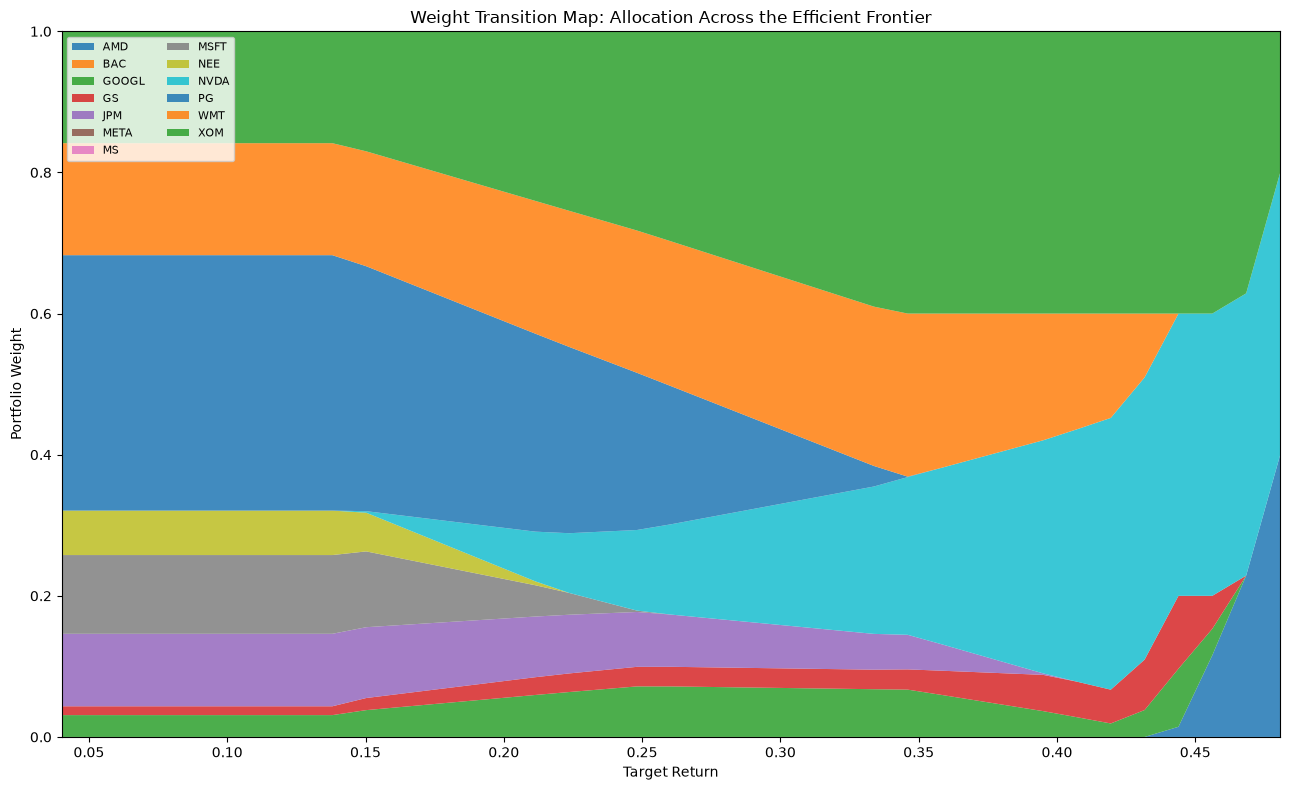

In [203]:
fig, ax = plt.subplots(figsize=(13, 8))

# Stacked area: at each target return (x), stack each asset's weight (y) on top of the others
ax.stackplot(weights_df.index,
             weights_df.T.values,          # transpose so each asset is a layer
             labels=weights_df.columns,
             alpha=0.85)

ax.set_title("Weight Transition Map: Allocation Across the Efficient Frontier")
ax.set_xlabel("Target Return")
ax.set_ylabel("Portfolio Weight")
ax.set_ylim(0, 1)                           # weights sum to 1 (100%)
ax.legend(loc="upper left", fontsize=8, ncol=2)
ax.margins(x=0)
plt.tight_layout()
plt.savefig("transition_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [205]:
#lets try teh same across GIC Sectors
import numpy as np
import pandas as pd
from pypfopt import EfficientFrontier

# --- Build sector-level inputs from the sector return series we already made ---
# Annualize: mean daily return * 252 = expected annual return per sector
sector_mu = sector_returns.mean() * 252

# Annualized covariance matrix between sectors (daily cov * 252)
sector_S = sector_returns.cov() * 252

print("Sector expected returns (annualized):")
print(sector_mu.sort_values(ascending=False))

Sector expected returns (annualized):
Energy                    0.317522
Information Technology    0.253576
Industrials               0.168808
Financials                0.151945
Consumer Discretionary    0.151247
Materials                 0.113774
Health Care               0.102202
Real Estate               0.100016
Communication Services    0.098087
Utilities                 0.091216
Consumer Staples          0.056993
dtype: float64


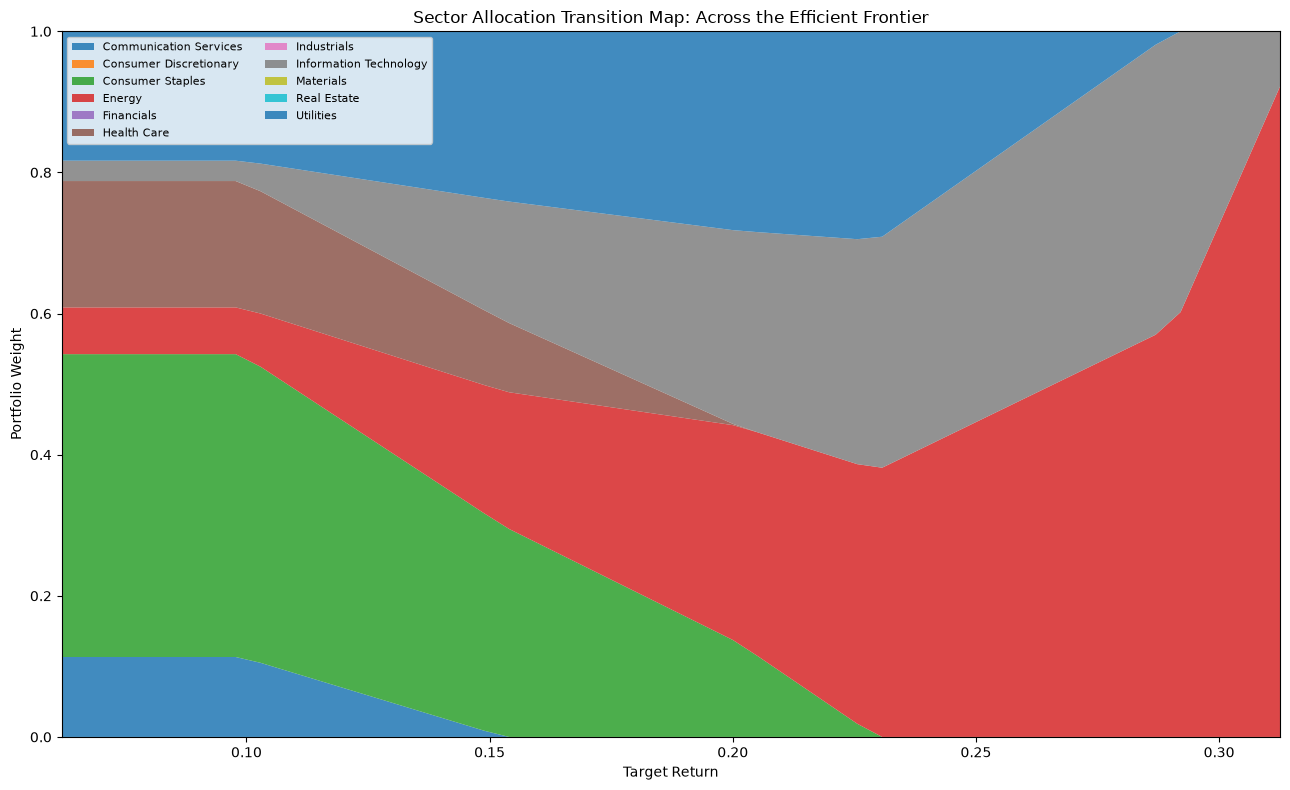

In [209]:
import matplotlib.pyplot as plt

# Sweep target returns across the sector frontier
sec_range = np.linspace(sector_mu.min() + 0.005, sector_mu.max() - 0.005, 50)

sec_weights = []
for target in sec_range:
    ef_s = EfficientFrontier(sector_mu, sector_S)   # fresh optimizer each loop
    try:
        ef_s.efficient_return(target)               # min-risk portfolio hitting this return
        sec_weights.append(ef_s.clean_weights())
    except Exception:
        sec_weights.append(None)

# Assemble into a DataFrame (rows = target returns, cols = sectors)
sec_weights_df = pd.DataFrame(
    [w for w in sec_weights if w is not None],
    index=[r for r, w in zip(sec_range, sec_weights) if w is not None]
)

# --- Stacked-area transition map across sectors ---
fig, ax = plt.subplots(figsize=(13, 8))
ax.stackplot(sec_weights_df.index,
             sec_weights_df.T.values,           # each sector = one layer
             labels=sec_weights_df.columns,
             alpha=0.85)

ax.set_title("Sector Allocation Transition Map: Across the Efficient Frontier")
ax.set_xlabel("Target Return")
ax.set_ylabel("Portfolio Weight")
ax.set_ylim(0, 1)
ax.legend(loc="upper left", fontsize=8, ncol=2)
ax.margins(x=0)
plt.tight_layout()
plt.savefig("sector_transition_map.png", dpi=150, bbox_inches="tight")
plt.show()

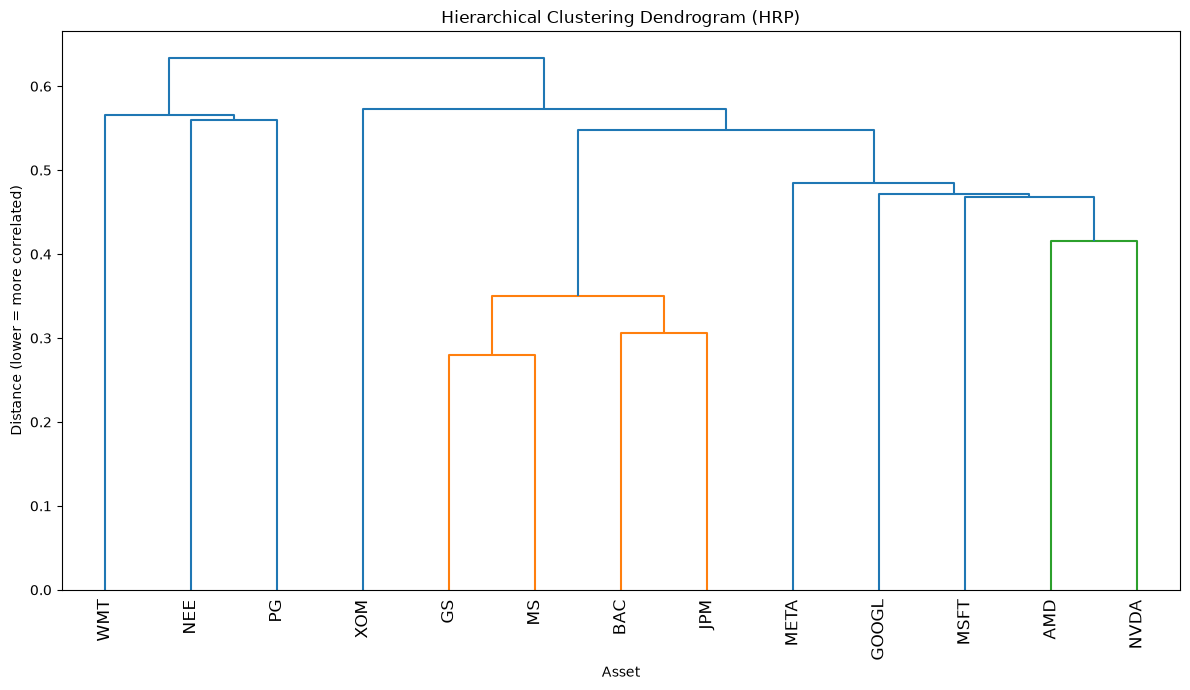

In [211]:
#I read Hierarchical Risk parity and dendograms on google, imma try it onmy initial 13 stocs, 250 is much to handle
import matplotlib.pyplot as plt
from pypfopt import HRPOpt

# HRP works directly on returns (not mu/S) — it clusters by correlation structure
hrp = HRPOpt(returns)          # 'returns' = your 13-asset daily returns
hrp_weights = hrp.optimize()   # runs the full HRP algorithm

# --- Draw the dendrogram: the clustering tree at the heart of HRP ---
import scipy.cluster.hierarchy as sch
import scipy.spatial.distance as ssd
import numpy as np

# Build the distance matrix HRP uses: distance = sqrt(0.5 * (1 - correlation))
corr = returns.corr()
dist = np.sqrt(0.5 * (1 - corr))                 # correlated assets -> small distance
condensed = ssd.squareform(dist, checks=False)   # scipy wants condensed form
linkage = sch.linkage(condensed, method="single")  # single-linkage clustering (HRP default)

fig, ax = plt.subplots(figsize=(12, 7))
sch.dendrogram(linkage, labels=corr.columns.tolist(), ax=ax, leaf_rotation=90)
ax.set_title("Hierarchical Clustering Dendrogram (HRP)")
ax.set_xlabel("Asset")
ax.set_ylabel("Distance (lower = more correlated)")
plt.tight_layout()
plt.savefig("hrp_dendrogram.png", dpi=150, bbox_inches="tight")
plt.show()

In [213]:
import pandas as pd

# Show HRP weights, sorted
hrp_w = pd.Series(hrp_weights).sort_values(ascending=False)
print("HRP weights:")
print(hrp_w.round(4))

hrp.portfolio_performance(verbose=True)   # HRP's expected return, vol, Sharpe

HRP weights:
PG       0.2033
WMT      0.1810
XOM      0.1158
NEE      0.0921
BAC      0.0760
JPM      0.0749
GS       0.0580
MS       0.0570
MSFT     0.0526
GOOGL    0.0401
META     0.0229
NVDA     0.0144
AMD      0.0120
dtype: float64
Expected annual return: 18.6%
Annual volatility: 14.2%
Sharpe Ratio: 1.31


(0.18568858068279281, 0.14213940086119423, 1.30638358933373)